# ДЗ 2. Прогнозирование продаж

Используем три ряда товара **20725, LUNCH BAG RED RETROSPOT**, подготовленные в ДЗ 1.
Сравниваем наивный прогноз, экспоненциальное сглаживание, ARIMA и бустинг на горизонтах 1/7/31/61 день, 1/4/8 недель и 1/2 месяца.
Основной результат берем на последнем разбиении, устойчивость проверяем по трем окнам.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import analysis_utils as au

plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid': True,
                     'grid.alpha': 0.25, 'font.family': 'DejaVu Sans'})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.3f}'.format)
ROOT = au.ROOT
for folder in ['data/processed', 'results', 'figures']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
print('Папка проекта:', ROOT.name)

Папка проекта: retail_homework


## 1. Данные из ДЗ 1

In [2]:
series = au.load_series()
metadata = json.loads((ROOT / 'data/processed/metadata.json').read_text())
print('Товар:', metadata['stock_code'], metadata['product'])
display(au.describe_series(series))
for y in series.values():
    assert y.notna().all() and y.index.is_unique and y.index.is_monotonic_increasing

Товар: 20725 LUNCH BAG RED RETROSPOT


,Начало,Конец,Длина,Пропуски,Нули,Среднее,Медиана,Станд. отклонение,Минимум,Максимум,CV,Доля нулей
Частота,,,,,,,,,,,,
День,2010-12-01,2011-12-08,373,0,76,52.308,36.000,62.346,0.000,432.000,1.192,0.204
Неделя,2010-12-12,2011-12-04,52,0,1,366.750,326.000,180.009,0.000,885.000,0.491,0.019
Месяц,2010-12-01,2011-11-01,12,0,0,1596.333,1613.000,460.607,732.000,2355.000,0.289,0.000


## 2. Схема эксперимента

Обучаемся на прошлом и сразу прогнозируем максимальный горизонт; короткие горизонты берем как префиксы, метрики считаем по всем первым h шагам.
Основной тест содержит 61 день, 8 недель или 2 месяца, а два дополнительных старта сдвинуты назад на один и два интервала по 7 дней, неделе или месяцу.
Окна перекрываются, параметры по тесту не меняем, а месячные выводы предварительные из-за 8-10 обучающих наблюдений.

In [3]:
plan = []
for frequency, y in series.items():
    h = max(au.HORIZONS[frequency])
    step = 7 if frequency == 'День' else 1
    for fold, offset in enumerate([2, 1, 0], 1):
        n = len(y) - h - step * offset
        plan.append({'Частота': frequency, 'Окно': fold, 'Обучение': n, 'Тест': h,
                     'Последняя метка обучения': y.index[n - 1], 'Первая метка теста': y.index[n]})
display(pd.DataFrame(plan))

,Частота,Окно,Обучение,Тест,Последняя метка обучения,Первая метка теста
0,День,1,298,61,2011-09-24,2011-09-25
1,День,2,305,61,2011-10-01,2011-10-02
2,День,3,312,61,2011-10-08,2011-10-09
3,Неделя,1,42,8,2011-09-25,2011-10-02
4,Неделя,2,43,8,2011-10-02,2011-10-09
5,Неделя,3,44,8,2011-10-09,2011-10-16
6,Месяц,1,8,2,2011-07-01,2011-08-01
7,Месяц,2,9,2,2011-08-01,2011-09-01
8,Месяц,3,10,2,2011-09-01,2011-10-01


## 3. Модели и признаки

Сравниваем наивный прогноз, экспоненциальное сглаживание, ARIMA(1, 1, 0) и бустинг из 80 деревьев глубины 2.
Бустинг использует прошлые значения, скользящие статистики и календарь, а на следующих шагах добавляет в историю собственные прогнозы.
Прогнозы ограничиваем снизу нулем и не округляем; настройки и функции находятся в `analysis_utils.py`.

In [4]:
# Проверяем признаки для первой даты дневного теста.
daily = series['День']
train_demo = daily.iloc[:-61]
date_demo = daily.index[-61]
feature_names = ['lag_1', 'lag_2', 'lag_7', 'lag_14', 'mean_14', 'std_14']
feature_names += ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс', 'month_sin', 'month_cos']
features = au.make_features(train_demo.to_list(), date_demo, 'День')
print('Дата прогноза:', date_demo.date())
display(pd.Series(features, index=feature_names, name='Значение'))

Дата прогноза: 2011-10-09


lag_1        0.000
lag_2       50.000
lag_7        0.000
lag_14      40.000
mean_14     48.429
std_14      35.038
Пн           0.000
Вт           0.000
Ср           0.000
Чт           0.000
Пт           0.000
Сб           0.000
Вс           1.000
month_sin   -0.866
month_cos    0.500
Name: Значение, dtype: float64

## 4. Метрики

Основная метрика MAE показывает ошибку в штуках, RMSE сильнее штрафует крупные промахи; обе сравниваем внутри одной частоты.
MASE делит MAE на среднюю обучающую разность с лагом 7 для дней и 1 для остальных рядов, поэтому значение ниже 1 не гарантирует победу над наивным методом на тесте.
sMAPE считаем как среднее 200|факт - прогноз| / (|факт| + |прогноз|) с нулевым вкладом для двух нулей, а MAPE исключаем из-за нулевых продаж.

In [5]:
# Простой пример проверяет соглашение для двух нулей.
example = au.forecast_metrics([0., 2.], [0., 4.], [1., 2., 3.], 'Месяц')
assert np.isclose(example['MAE'], 1)
assert np.isclose(example['RMSE'], np.sqrt(2))
assert np.isclose(example['MASE'], 1)
assert np.isclose(example['sMAPE'], 100 / 3)
print(example)

{'MAE': np.float64(1.0), 'RMSE': np.float64(1.4142135623730951), 'MASE': np.float64(1.0), 'sMAPE': np.float64(33.333333333333336)}


## 5. Обучение и прогнозы

In [6]:
predictions, metrics, splits, diagnostics = au.run_experiments(series)
print('Строк прогнозов:', len(predictions))
print('Комбинаций модель / частота / горизонт / окно:', len(metrics))
display(splits)
if len(diagnostics):
    display(diagnostics)

Строк прогнозов: 1392
Комбинаций модель / частота / горизонт / окно: 108


,Частота,Окно,Обучение,Начало обучения,Конец обучения,Начало теста,Конец теста,Тест
0,День,1,298,2010-12-01,2011-09-24,2011-09-25,2011-11-24,61
1,День,2,305,2010-12-01,2011-10-01,2011-10-02,2011-12-01,61
2,День,3,312,2010-12-01,2011-10-08,2011-10-09,2011-12-08,61
3,Неделя,1,42,2010-12-12,2011-09-25,2011-10-02,2011-11-20,8
4,Неделя,2,43,2010-12-12,2011-10-02,2011-10-09,2011-11-27,8
5,Неделя,3,44,2010-12-12,2011-10-09,2011-10-16,2011-12-04,8
6,Месяц,1,8,2010-12-01,2011-07-01,2011-08-01,2011-09-01,2
7,Месяц,2,9,2010-12-01,2011-08-01,2011-09-01,2011-10-01,2
8,Месяц,3,10,2010-12-01,2011-09-01,2011-10-01,2011-11-01,2


In [7]:
# Для каждой комбинации должны быть все шаги прогноза.
keys = ['Частота', 'Окно', 'Модель', 'Горизонт']
counts = predictions.groupby(keys).size().reset_index(name='Строк')
assert (counts['Горизонт'] == counts['Строк']).all()
assert len(metrics) == 3 * len(au.MODELS) * sum(map(len, au.HORIZONS.values()))
assert not metrics.duplicated(keys).any()
assert np.isfinite(metrics[['MAE', 'RMSE', 'MASE', 'sMAPE']]).all().all()
assert (predictions['Прогноз'] >= 0).all()
assert (predictions['Дата'] > predictions['Дата прогноза']).all()
for _, group in predictions.groupby(['Частота', 'Окно', 'Горизонт', 'Шаг']):
    assert group['Факт'].nunique() == 1 and group['Дата'].nunique() == 1

## 6. Результаты на последнем разбиении

Окно 3 является основным. Лучший результат выбираем по MAE отдельно для каждой частоты и горизонта.
Это описание полученного теста, а не независимая проверка выбранной модели для будущего применения.

In [8]:
final_metrics = metrics[metrics['Окно'].eq(3)].drop(columns='Окно').copy()
display(final_metrics.sort_values(['Частота', 'Горизонт', 'MAE']))
winner_idx = final_metrics.groupby(['Частота', 'Горизонт'])['MAE'].idxmin()
winners = final_metrics.loc[winner_idx].sort_values(['Частота', 'Горизонт'])
display(winners)

,Частота,Модель,Горизонт,MAE,RMSE,MASE,sMAPE
32,День,Наивная,1,2.000,2.000,0.039,200.000
40,День,ARIMA,1,18.228,18.228,0.353,164.009
44,День,Бустинг,1,25.873,25.873,0.500,173.220
36,День,Эксп. сглаживание,1,28.359,28.359,0.549,175.277
33,День,Наивная,7,29.286,46.326,0.567,61.395
45,День,Бустинг,7,31.652,37.669,0.612,82.139
37,День,Эксп. сглаживание,7,31.844,41.527,0.616,85.531
41,День,ARIMA,7,57.049,72.858,1.104,147.629
34,День,Наивная,31,33.387,46.233,0.646,77.319
38,День,Эксп. сглаживание,31,35.080,41.996,0.679,92.098


,Частота,Модель,Горизонт,MAE,RMSE,MASE,sMAPE
32,День,Наивная,1,2.000,2.000,0.039,200.000
33,День,Наивная,7,29.286,46.326,0.567,61.395
34,День,Наивная,31,33.387,46.233,0.646,77.319
39,День,Эксп. сглаживание,61,31.022,41.755,0.600,77.886
100,Месяц,Наивная,1,448.000,448.000,0.837,28.194
101,Месяц,Наивная,2,314.000,341.397,0.587,18.826
75,Неделя,Эксп. сглаживание,1,43.232,43.232,0.214,10.259
73,Неделя,Наивная,4,44.000,64.850,0.218,12.461
83,Неделя,Бустинг,8,98.253,142.385,0.486,23.410


На горизонте двух месяцев наивный метод и сглаживание дают одинаковую MAE = 314.
В таблице оставлен первый метод при равенстве, поэтому его победа не уникальна.

In [9]:
# Сравниваем победителя с наивным прогнозом на том же тесте.
baseline = final_metrics[final_metrics['Модель'].eq('Наивная')][['Частота', 'Горизонт', 'MAE']]
comparison = winners.merge(baseline, on=['Частота', 'Горизонт'], suffixes=('', '_naive'))
comparison['Снижение MAE, %'] = 100 * (1 - comparison['MAE'] / comparison['MAE_naive'])
display(comparison[['Частота', 'Горизонт', 'Модель', 'MAE', 'MAE_naive', 'Снижение MAE, %']])

,Частота,Горизонт,Модель,MAE,MAE_naive,"Снижение MAE, %"
0,День,1,Наивная,2.000,2.000,0.000
1,День,7,Наивная,29.286,29.286,0.000
2,День,31,Наивная,33.387,33.387,0.000
3,День,61,Эксп. сглаживание,31.022,31.328,0.975
4,Месяц,1,Наивная,448.000,448.000,0.000
5,Месяц,2,Наивная,314.000,314.000,0.000
6,Неделя,1,Эксп. сглаживание,43.232,121.000,64.271
7,Неделя,4,Наивная,44.000,44.000,0.000
8,Неделя,8,Бустинг,98.253,99.125,0.880


## 7. Факт и прогноз на каждом горизонте

На графиках показаны последние наблюдения обучения и весь соответствующий тестовый горизонт.
На горизонте 1 прогнозы отображаются отдельными точками.

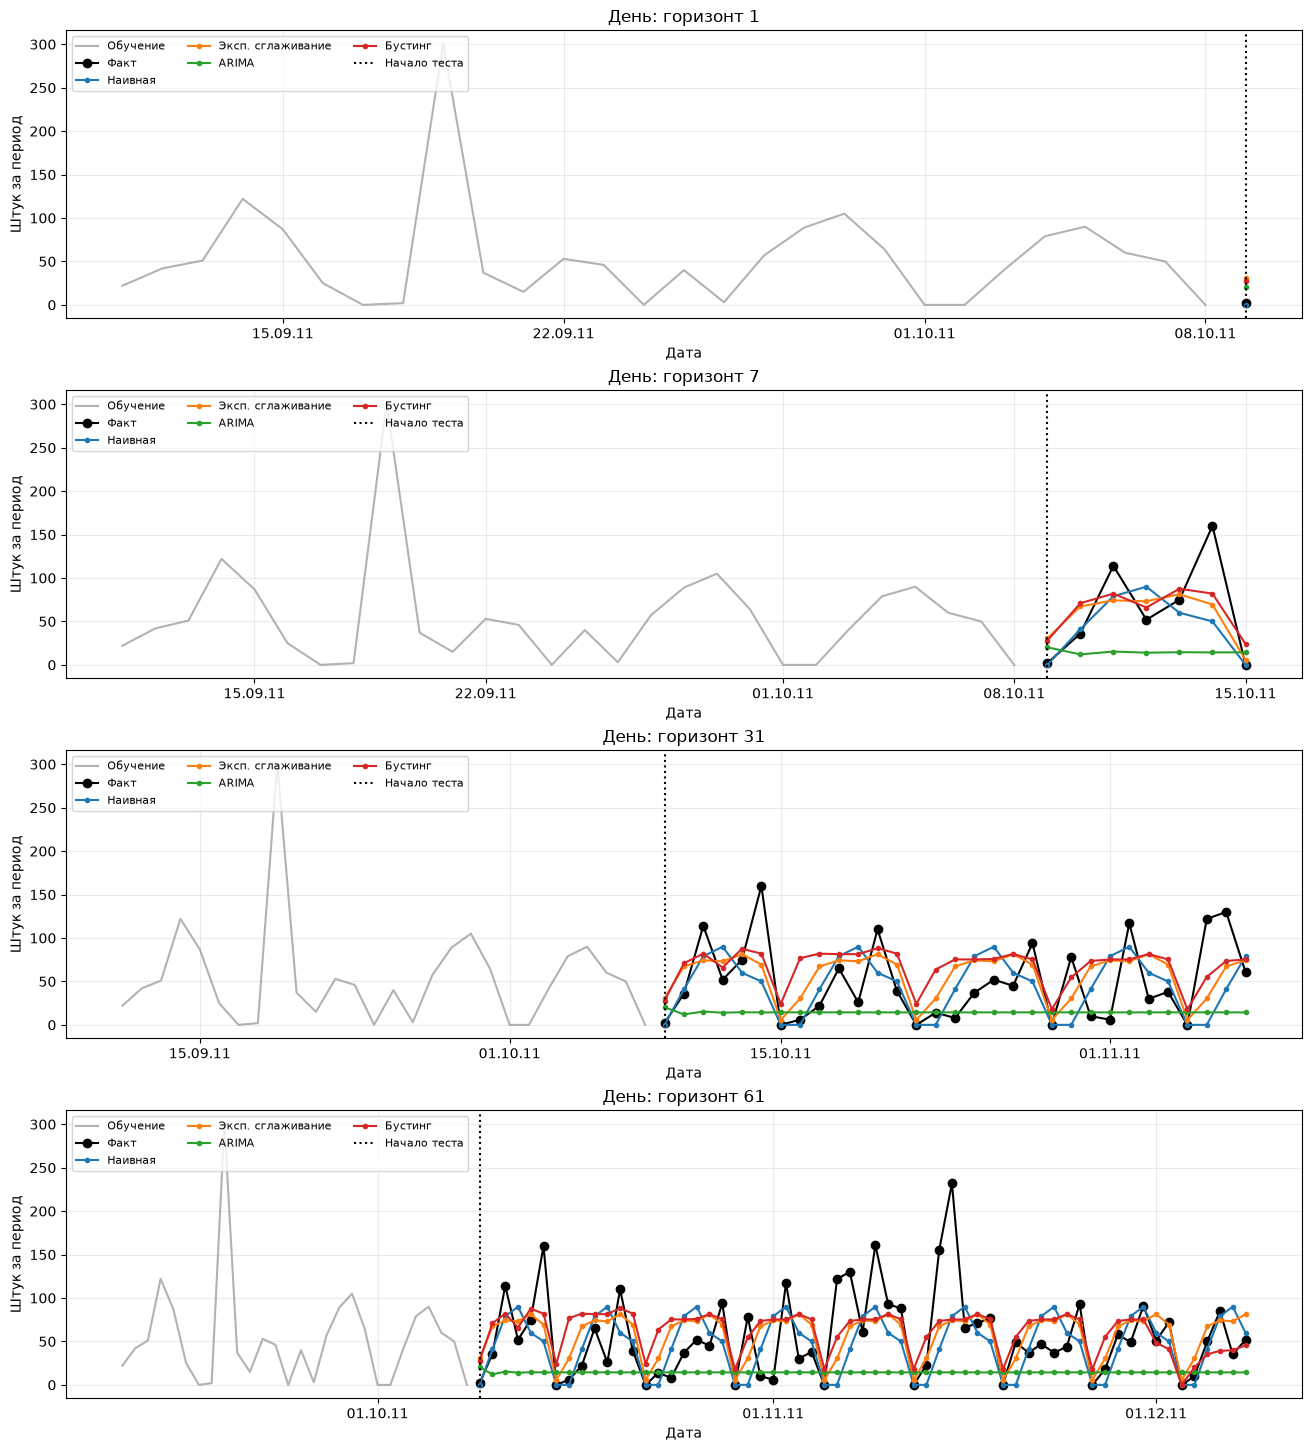

In [10]:
import matplotlib.dates as mdates

def plot_forecasts(frequency):
    horizons = au.HORIZONS[frequency]
    y = series[frequency]
    origin = len(y) - max(horizons)
    history = y.iloc[max(0, origin - min(28, origin)):origin]
    fig, axes = plt.subplots(len(horizons), 1, figsize=(13, 3.6 * len(horizons)),
                             squeeze=False, layout='constrained')
    for ax, h in zip(axes[:, 0], horizons):
        actual = y.iloc[origin:origin + h]
        ax.plot(history.index, history, color='gray', alpha=0.6, label='Обучение')
        ax.plot(actual.index, actual, color='black', marker='o', label='Факт')
        selection = predictions[(predictions['Частота'] == frequency)
                                & (predictions['Окно'] == 3) & (predictions['Горизонт'] == h)]
        for model, group in selection.groupby('Модель', sort=False):
            ax.plot(group['Дата'], group['Прогноз'], marker='.', label=model)
        ax.axvline(actual.index[0], color='black', ls=':', label='Начало теста')
        ax.set(title=f'{frequency}: горизонт {h}', xlabel='Дата', ylabel='Штук за период')
        ax.legend(loc='upper left', ncol=3, fontsize=8)
        ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=7))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.%y'))
    name = {'День': 'daily', 'Неделя': 'weekly', 'Месяц': 'monthly'}[frequency]
    fig.savefig(ROOT / f'figures/forecast_{name}.png', dpi=150)
    plt.show()

plot_forecasts('День')

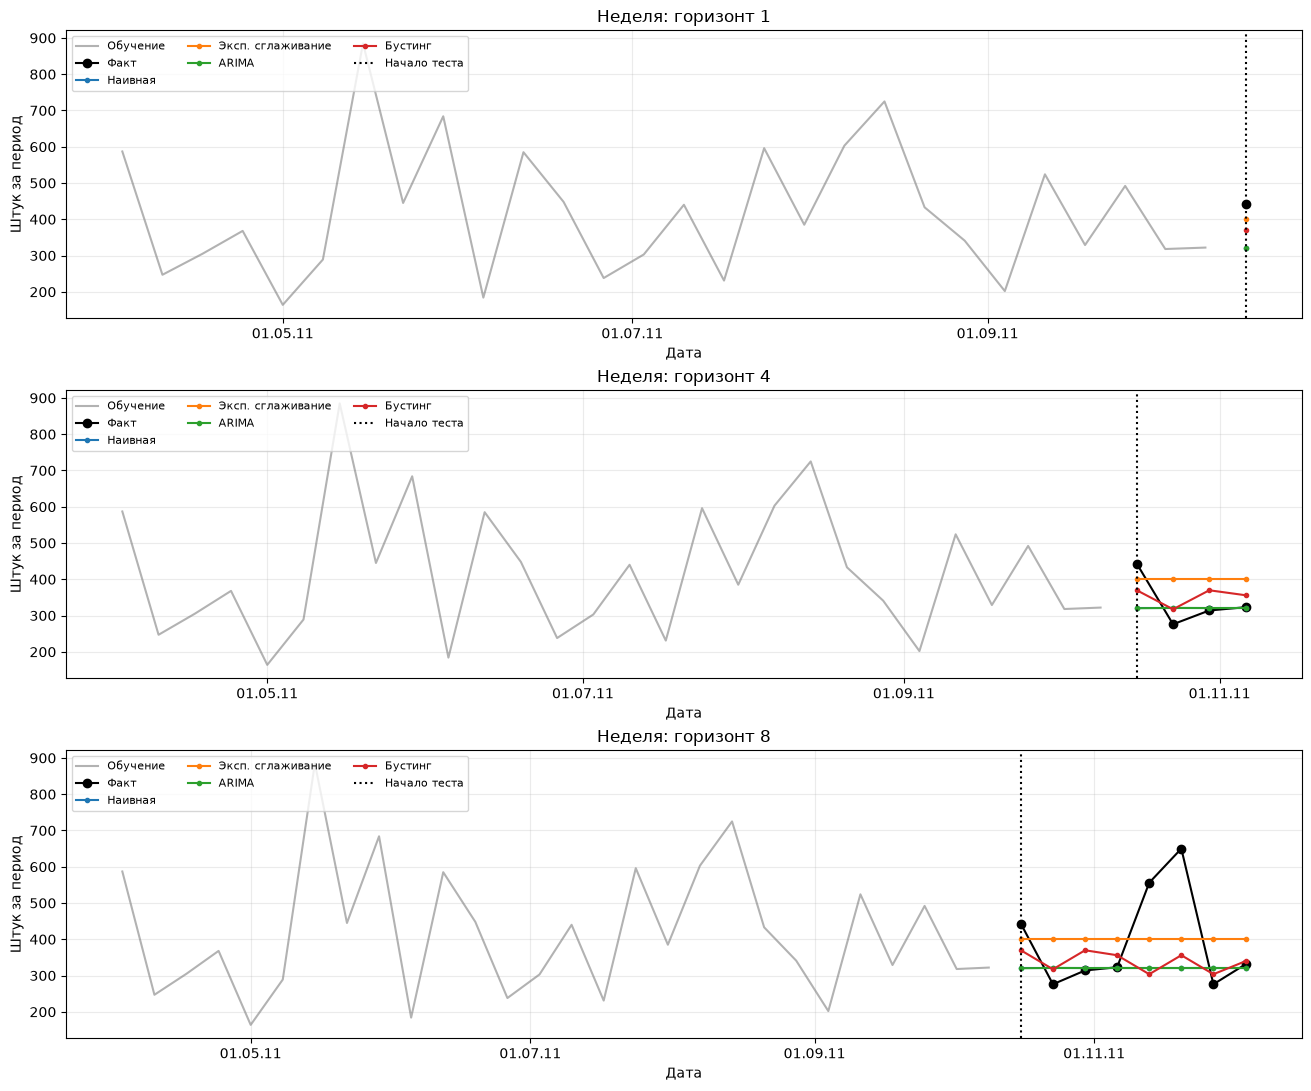

In [11]:
plot_forecasts('Неделя')

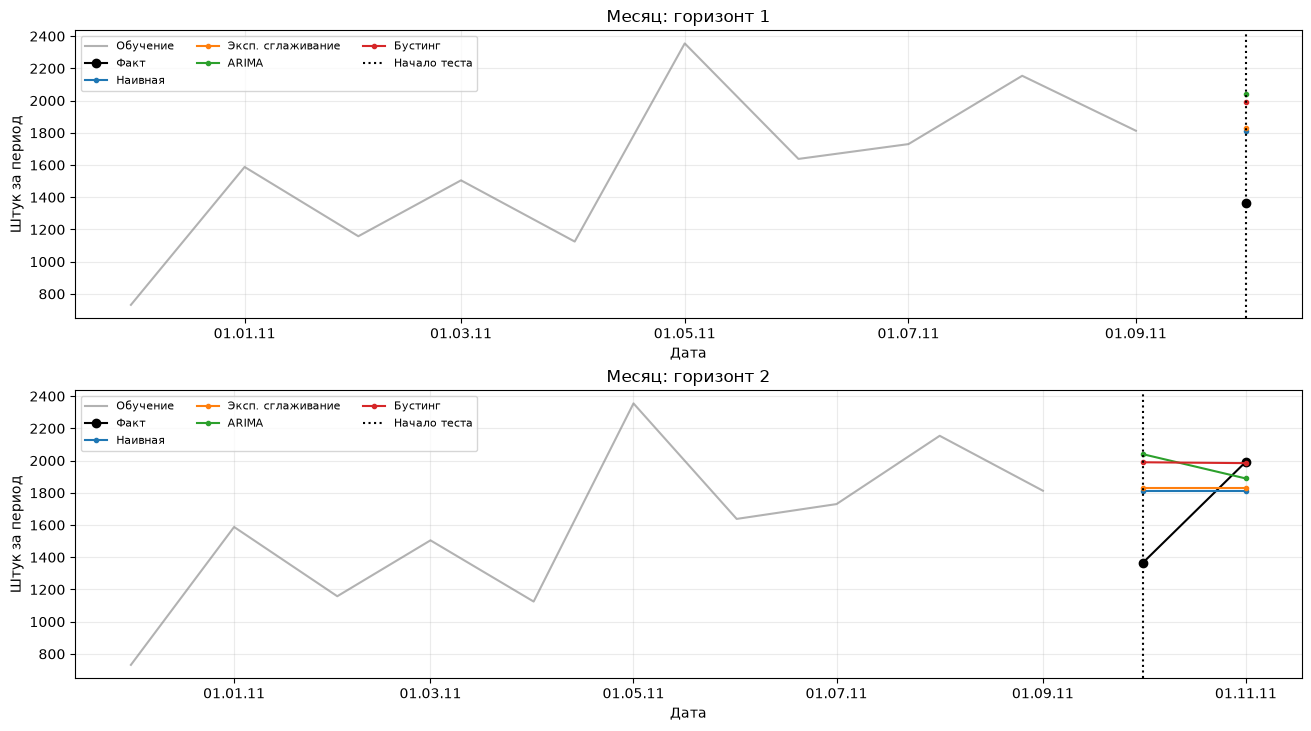

In [12]:
plot_forecasts('Месяц')

Длинный горизонт включает больше разных дней или периодов. Поэтому средняя ошибка не обязана
расти монотонно: один крупный заказ или неудачный первый день может изменить картину.
Бустинг на длинном горизонте использует собственные прогнозы в лагах и может накапливать ошибку.

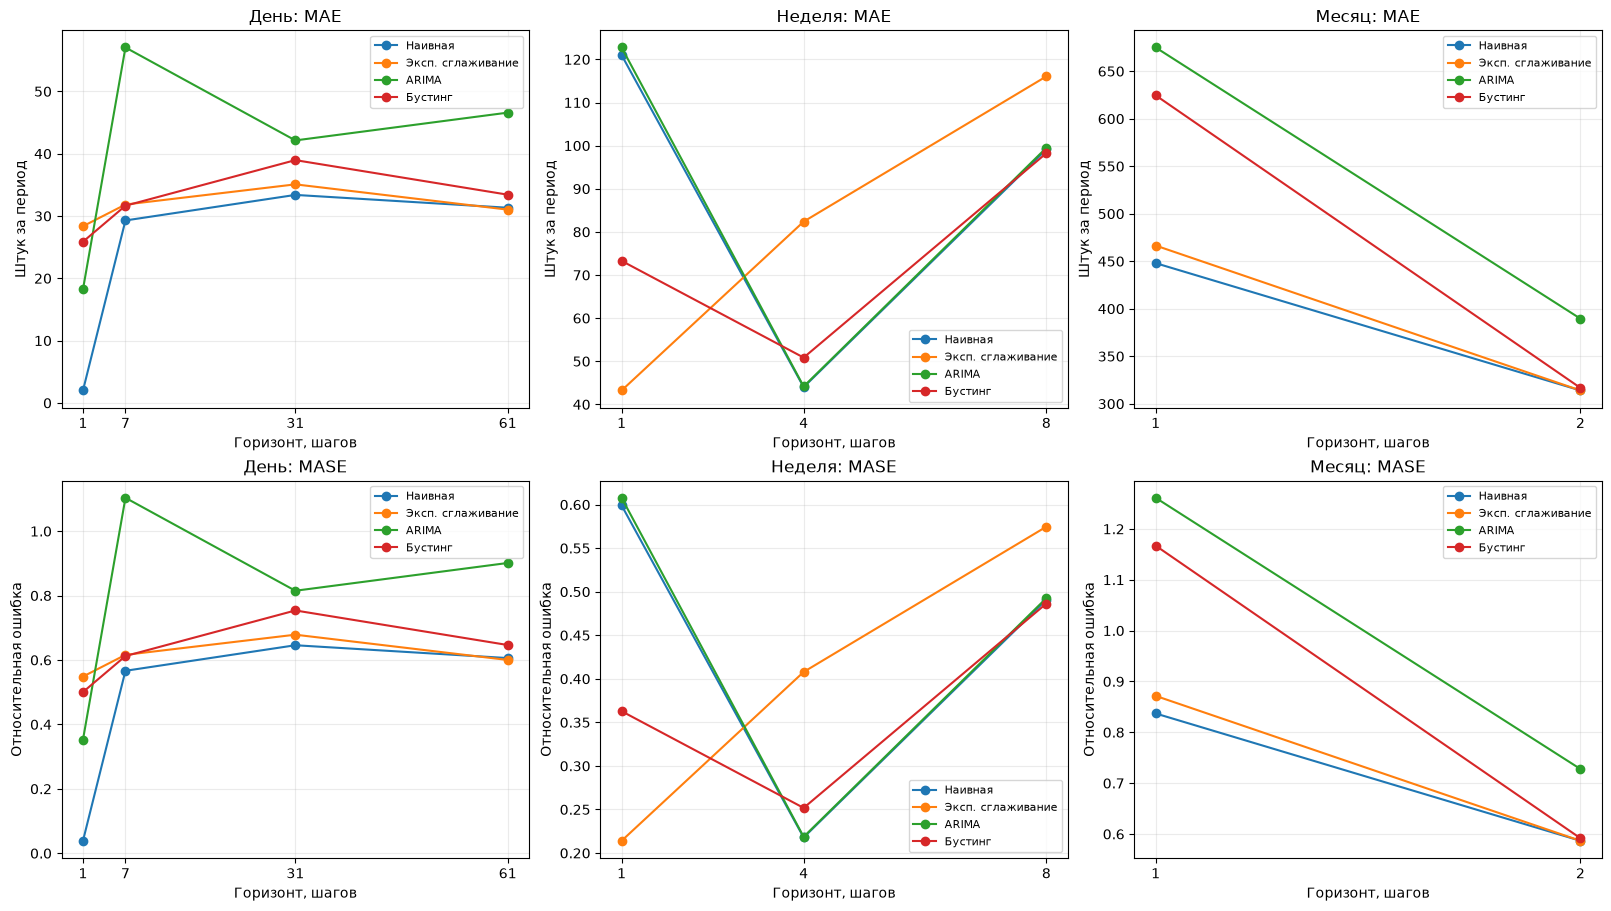

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), layout='constrained')
for j, frequency in enumerate(au.HORIZONS):
    data = final_metrics[final_metrics['Частота'] == frequency]
    for i, metric in enumerate(['MAE', 'MASE']):
        ax = axes[i, j]
        for model, group in data.groupby('Модель', sort=False):
            group = group.sort_values('Горизонт')
            ax.plot(group['Горизонт'], group[metric], marker='o', label=model)
        ax.set(title=f'{frequency}: {metric}', xlabel='Горизонт, шагов',
               ylabel='Штук за период' if metric == 'MAE' else 'Относительная ошибка',
               xticks=au.HORIZONS[frequency])
        ax.legend(fontsize=8)
fig.savefig(ROOT / 'figures/metrics_by_horizon.png', dpi=150)
plt.show()

In [14]:
changes = []
for (frequency, model), group in final_metrics.groupby(['Частота', 'Модель']):
    group = group.sort_values('Горизонт')
    first, last = group.iloc[0], group.iloc[-1]
    changes.append({'Частота': frequency, 'Модель': model,
                    'MAE короткий': first.MAE, 'MAE длинный': last.MAE,
                    'Изменение MAE': last.MAE - first.MAE,
                    'Монотонный рост': bool(group.MAE.is_monotonic_increasing)})
changes = pd.DataFrame(changes)
display(changes)

,Частота,Модель,MAE короткий,MAE длинный,Изменение MAE,Монотонный рост
0,День,ARIMA,18.228,46.592,28.363,False
1,День,Бустинг,25.873,33.422,7.550,False
2,День,Наивная,2.000,31.328,29.328,False
3,День,Эксп. сглаживание,28.359,31.022,2.664,False
4,Месяц,ARIMA,674.995,389.552,-285.443,False
5,Месяц,Бустинг,624.609,316.686,-307.924,False
6,Месяц,Наивная,448.000,314.000,-134.000,False
7,Месяц,Эксп. сглаживание,466.515,314.000,-152.515,False
8,Неделя,ARIMA,122.765,99.510,-23.254,False
9,Неделя,Бустинг,73.283,98.253,24.970,False


## 8. Устойчивость к дате начала прогноза

Показываем среднее и стандартное отклонение метрик по трем окнам.
Окна пересекаются: стандартное отклонение не является доверительным интервалом.
Одинаковые будущие даты могут участвовать в прогнозах с разных точек старта, что здесь намеренно.

In [15]:
rolling = metrics.groupby(['Частота', 'Горизонт', 'Модель']).agg(
    MAE_mean=('MAE', 'mean'), MAE_std=('MAE', 'std'),
    RMSE_mean=('RMSE', 'mean'), MASE_mean=('MASE', 'mean'), sMAPE_mean=('sMAPE', 'mean')).reset_index()
rolling_winners = rolling.loc[rolling.groupby(['Частота', 'Горизонт']).MAE_mean.idxmin()]
display(rolling_winners)
stability = winners[['Частота', 'Горизонт', 'Модель']].merge(
    rolling_winners[['Частота', 'Горизонт', 'Модель']], on=['Частота', 'Горизонт'],
    suffixes=('_последнее', '_три_окна'))
stability['Совпадает'] = stability.Модель_последнее == stability.Модель_три_окна
display(stability)

,Частота,Горизонт,Модель,MAE_mean,MAE_std,RMSE_mean,MASE_mean,sMAPE_mean
0,День,1,ARIMA,21.829,3.953,21.829,0.420,145.374
7,День,7,Эксп. сглаживание,23.894,6.984,30.618,0.460,77.434
11,День,31,Эксп. сглаживание,30.837,4.008,37.263,0.593,88.807
15,День,61,Эксп. сглаживание,31.648,0.633,42.030,0.609,79.477
19,Месяц,1,Эксп. сглаживание,392.113,326.633,392.113,0.700,22.751
21,Месяц,2,Бустинг,345.910,31.587,427.044,0.619,19.954
27,Неделя,1,Эксп. сглаживание,76.992,30.171,76.992,0.373,20.469
28,Неделя,4,ARIMA,74.452,28.739,87.643,0.361,20.589
32,Неделя,8,ARIMA,112.067,11.393,140.266,0.545,27.108


,Частота,Горизонт,Модель_последнее,Модель_три_окна,Совпадает
0,День,1,Наивная,ARIMA,False
1,День,7,Наивная,Эксп. сглаживание,False
2,День,31,Наивная,Эксп. сглаживание,False
3,День,61,Эксп. сглаживание,Эксп. сглаживание,True
4,Месяц,1,Наивная,Эксп. сглаживание,False
5,Месяц,2,Наивная,Бустинг,False
6,Неделя,1,Эксп. сглаживание,Эксп. сглаживание,True
7,Неделя,4,Наивная,ARIMA,False
8,Неделя,8,Бустинг,ARIMA,False


## 9. Сохранение результатов и выводы

Ошибки связаны с крупными заказами, днями без продаж и изменениями уровня ряда.
Бустинг может накапливать ошибки, особенно на месячных данных с 6-8 примерами после формирования лагов.
Для надежного выбора модели нужны более длинная история и отдельный будущий тест.

In [16]:
outputs = {'predictions.csv': predictions, 'metrics_all_windows.csv': metrics,
           'metrics_final.csv': final_metrics, 'splits.csv': splits,
           'model_warnings.csv': diagnostics, 'winners.csv': winners,
           'rolling_summary.csv': rolling, 'rolling_winners.csv': rolling_winners,
           'horizon_changes.csv': changes, 'winner_stability.csv': stability}
for name, table in outputs.items():
    table.to_csv(ROOT / 'results' / name, index=False)

### Что показывают прогнозы

Победители зависят от горизонта, а при усреднении трех окон меняются в 7 из 9 случаев.
На двух месяцах у наивного метода и сглаживания одинаковая MAE = 314, поэтому указанная в таблице победа наивного метода не уникальна.
Ошибка не обязана расти с горизонтом, а небольшие различия и короткая месячная история ограничивают надежность выводов.